In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mannugaurav/pad-ufes-20/metadata.csv
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_100_393_595.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_100_393_898.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_101_1041_651.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_101_1041_658.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_101_1041_898.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_104_1754_276.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_104_1755_320.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_104_1756_151.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_106_158_249.png
/kaggle/input/datasets/mannugaurav/pad-ufes-20/imgs_part_1/imgs_part_1/PAT_106_158_270.png
/kaggle/input/datasets/m

In [2]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

for item in sorted(INPUT_DIR.iterdir()):
    print("\nDataset:", item.name)
    for file in item.rglob("*"):
        if file.is_file():
            print("  ", file.name)


Dataset: datasets
   metadata.csv
   best_clinical_svm.pkl
   best_multimodal_model.pth
   best_resnet50.pth
   cleaned_metadata_with_splits.csv
   PAT_1094_381_355.png
   PAT_1094_381_446.png
   PAT_1094_381_85.png
   PAT_1100_402_375.png
   PAT_1102_408_613.png
   PAT_1105_420_520.png
   PAT_1107_427_352.png
   PAT_1109_436_141.png
   PAT_1109_437_254.png
   PAT_1112_455_845.png
   PAT_1113_458_387.png
   PAT_1118_470_710.png
   PAT_1119_472_513.png
   PAT_1122_479_664.png
   PAT_1124_489_151.png
   PAT_1125_492_523.png
   PAT_1127_496_945.png
   PAT_1128_497_29.png
   PAT_1128_497_322.png
   PAT_1129_498_930.png
   PAT_1130_501_181.png
   PAT_1132_508_325.png
   PAT_1133_510_956.png
   PAT_1136_517_92.png
   PAT_1138_520_154.png
   PAT_1139_523_682.png
   PAT_1141_526_416.png
   PAT_1145_534_524.png
   PAT_1145_534_529.png
   PAT_1148_542_708.png
   PAT_1151_551_241.png
   PAT_1153_555_98.png
   PAT_1158_570_376.png
   PAT_1161_578_233.png
   PAT_1170_608_367.png
   PAT_1170_609_37

In [3]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

required_files = [
    "metadata.csv",
    "cleaned_metadata_with_splits.csv",
    "best_clinical_svm.pkl",
    "best_resnet50.pth",
    "best_multimodal_model.pth"
]

for filename in required_files:
    matches = list(INPUT_DIR.rglob(filename))

    if matches:
        print(f"FOUND: {filename}")
        print(f"Path: {matches[0]}")
    else:
        print(f"MISSING: {filename}")

FOUND: metadata.csv
Path: /kaggle/input/datasets/mannugaurav/pad-ufes-20/metadata.csv
FOUND: cleaned_metadata_with_splits.csv
Path: /kaggle/input/datasets/mannugaurav/pad-ufes-20-cleaned-metadata/cleaned_metadata_with_splits.csv
FOUND: best_clinical_svm.pkl
Path: /kaggle/input/datasets/mannugaurav/pad-ufes-20-clinical-svm-model/best_clinical_svm.pkl
FOUND: best_resnet50.pth
Path: /kaggle/input/datasets/mannugaurav/pad-ufes-20-resnet50-model/best_resnet50.pth
FOUND: best_multimodal_model.pth
Path: /kaggle/input/datasets/mannugaurav/pad-ufes-20-multimodal-model/best_multimodal_model.pth


In [4]:
import pandas as pd
from pathlib import Path

CLEANED_CSV = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20-cleaned-metadata/cleaned_metadata_with_splits.csv"
)

df = pd.read_csv(CLEANED_CSV)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

clinical_features = [
    "age", "region", "itch", "hurt", "bleed", "elevation"
]

print("Complete dataset:", df.shape)
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))

print("\nTest class distribution:")
print(test_df["target"].value_counts())

print("\nMissing clinical values in test set:")
print(test_df[clinical_features].isnull().sum())

Complete dataset: (2271, 29)
Training records: 1608
Validation records: 305
Test records: 358

Test class distribution:
target
Malignant       172
Precancerous    111
Benign           75
Name: count, dtype: int64

Missing clinical values in test set:
age          0
region       0
itch         0
hurt         0
bleed        0
elevation    0
dtype: int64


In [5]:
DATASET_DIR = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20"
)

image_lookup = {
    path.name: str(path)
    for path in DATASET_DIR.rglob("*.png")
}

test_df["image_path"] = test_df["img_id"].map(image_lookup)

print("Test records:", len(test_df))
print("Matched images:", test_df["image_path"].notna().sum())
print("Missing images:", test_df["image_path"].isna().sum())

print("\nSample image paths:")
print(test_df[["img_id", "image_path"]].head())

Test records: 358
Matched images: 358
Missing images: 0

Sample image paths:
                   img_id                                         image_path
8   PAT_1995_4080_695.png  /kaggle/input/datasets/mannugaurav/pad-ufes-20...
21  PAT_1653_2916_346.png  /kaggle/input/datasets/mannugaurav/pad-ufes-20...
27    PAT_359_4450_86.png  /kaggle/input/datasets/mannugaurav/pad-ufes-20...
28    PAT_107_160_609.png  /kaggle/input/datasets/mannugaurav/pad-ufes-20...
33   PAT_724_1369_896.png  /kaggle/input/datasets/mannugaurav/pad-ufes-20...


In [6]:
!pip install scikit-learn==1.7.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 137.8 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [7]:
import joblib

CLINICAL_MODEL_PATH = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20-clinical-svm-model/best_clinical_svm.pkl"
)

clinical_model = joblib.load(CLINICAL_MODEL_PATH)

print("Clinical SVM loaded successfully.")
print("Model:", clinical_model.named_steps["classifier"])
print("Classes:", clinical_model.classes_)

Clinical SVM loaded successfully.
Model: SVC(C=1, class_weight='balanced', probability=True, random_state=42)
Classes: ['Benign' 'Malignant' 'Precancerous']


In [8]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.7.2


In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_MODEL_PATH = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20-resnet50-model/best_resnet50.pth"
)

image_checkpoint = torch.load(
    IMAGE_MODEL_PATH,
    map_location=device,
    weights_only=True
)

image_model = models.resnet50(weights=None)
image_model.fc = nn.Linear(image_model.fc.in_features, 3)

image_model.load_state_dict(image_checkpoint["model_state_dict"])
image_model = image_model.to(device)
image_model.eval()

print("Image-only ResNet50 loaded successfully.")
print("Device:", device)

Image-only ResNet50 loaded successfully.
Device: cuda


In [10]:
class MultimodalSkinLesionModel(nn.Module):

    def __init__(self, image_encoder, clinical_input_dim=27):
        super().__init__()

        self.image_encoder = image_encoder

        self.clinical_branch = nn.Sequential(
            nn.Linear(clinical_input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(2048 + 32, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 3)
        )

    def forward(self, images, clinical_data):

        with torch.no_grad():
            image_features = self.image_encoder(images)

        clinical_features = self.clinical_branch(clinical_data)

        combined_features = torch.cat(
            (image_features, clinical_features), dim=1
        )

        output = self.classifier(combined_features)

        return output

In [11]:
MULTIMODAL_MODEL_PATH = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20-multimodal-model/best_multimodal_model.pth"
)

multimodal_checkpoint = torch.load(
    MULTIMODAL_MODEL_PATH,
    map_location=device,
    weights_only=True
)

# Reuse the fine-tuned ResNet50 encoder
multimodal_image_encoder = models.resnet50(weights=None)
multimodal_image_encoder.fc = nn.Identity()

# Load the image encoder weights from the multimodal checkpoint
multimodal_image_encoder.load_state_dict({
    key.replace("image_encoder.", ""): value
    for key, value in multimodal_checkpoint["model_state_dict"].items()
    if key.startswith("image_encoder.")
})

multimodal_model = MultimodalSkinLesionModel(
    image_encoder=multimodal_image_encoder,
    clinical_input_dim=27
).to(device)

multimodal_model.load_state_dict(
    multimodal_checkpoint["model_state_dict"]
)

multimodal_model.eval()

print("Multimodal model loaded successfully.")
print("Device:", device)
print("Validation Macro-F1:",
      multimodal_checkpoint["validation_macro_f1"])

Multimodal model loaded successfully.
Device: cuda
Validation Macro-F1: 0.7978759452839151


In [12]:
# Get one test image
from PIL import Image
from torchvision import transforms

IMAGE_SIZE = 224

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

sample_row = test_df.iloc[0]

sample_image = Image.open(
    sample_row["image_path"]
).convert("RGB")

sample_tensor = eval_transform(sample_image).unsqueeze(0).to(device)

# Prepare clinical features
sample_clinical = clinical_model.named_steps["preprocessor"].transform(
    test_df.iloc[[0]][clinical_features]
)

sample_clinical = torch.tensor(
    sample_clinical.toarray().astype(np.float32),
    dtype=torch.float32
).to(device)

image_model.eval()
multimodal_model.eval()

with torch.no_grad():
    image_output = image_model(sample_tensor)
    multimodal_output = multimodal_model(
        sample_tensor, sample_clinical
    )

print("Image model output:", image_output.shape)
print("Multimodal model output:", multimodal_output.shape)

Image model output: torch.Size([1, 3])
Multimodal model output: torch.Size([1, 3])


In [13]:
from torch.utils.data import Dataset, DataLoader

label_mapping = {
    "Benign": 0,
    "Malignant": 1,
    "Precancerous": 2
}

class FinalTestDataset(Dataset):

    def __init__(self, dataframe, clinical_model, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.clinical_data = clinical_model.named_steps[
            "preprocessor"
        ].transform(
            self.dataframe[clinical_features]
        ).toarray().astype(np.float32)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)

        clinical = torch.tensor(
            self.clinical_data[index],
            dtype=torch.float32
        )

        label = label_mapping[row["target"]]

        return image, clinical, label


test_dataset = FinalTestDataset(
    test_df,
    clinical_model,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Test dataset size:", len(test_dataset))
print("Test batches:", len(test_loader))

Test dataset size: 358
Test batches: 12


In [14]:
from sklearn.metrics import accuracy_score, f1_score

# 1. Clinical-only predictions
X_test_clinical = test_df[clinical_features]

clinical_predictions = clinical_model.predict(X_test_clinical)
clinical_probabilities = clinical_model.predict_proba(X_test_clinical)

# 2. Image-only and multimodal predictions
image_predictions = []
image_probabilities = []

multimodal_predictions = []
multimodal_probabilities = []

true_labels = []

image_model.eval()
multimodal_model.eval()

with torch.no_grad():

    for images, clinical, labels in test_loader:

        images = images.to(device)
        clinical = clinical.to(device)

        # Image-only model
        image_outputs = image_model(images)
        image_probs = torch.softmax(image_outputs, dim=1)
        image_preds = torch.argmax(image_outputs, dim=1)

        # Multimodal model
        multimodal_outputs = multimodal_model(images, clinical)
        multimodal_probs = torch.softmax(multimodal_outputs, dim=1)
        multimodal_preds = torch.argmax(multimodal_outputs, dim=1)

        image_predictions.extend(image_preds.cpu().numpy())
        image_probabilities.extend(image_probs.cpu().numpy())

        multimodal_predictions.extend(multimodal_preds.cpu().numpy())
        multimodal_probabilities.extend(multimodal_probs.cpu().numpy())

        true_labels.extend(labels.numpy())

# Convert predictions into arrays
y_true = np.array(true_labels)

clinical_predictions = np.array(clinical_predictions)
clinical_probabilities = np.array(clinical_probabilities)

image_predictions = np.array(image_predictions)
image_probabilities = np.array(image_probabilities)

multimodal_predictions = np.array(multimodal_predictions)
multimodal_probabilities = np.array(multimodal_probabilities)

print("Test predictions generated successfully.")

print("Clinical predictions:", len(clinical_predictions))
print("Image predictions:", len(image_predictions))
print("Multimodal predictions:", len(multimodal_predictions))
print("True labels:", len(y_true))

Test predictions generated successfully.
Clinical predictions: 358
Image predictions: 358
Multimodal predictions: 358
True labels: 358


In [15]:
print("Clinical predictions defined:", "clinical_predictions" in globals())
print("Clinical probabilities defined:", "clinical_probabilities" in globals())

print("Image predictions defined:", "image_predictions" in globals())
print("Multimodal predictions defined:", "multimodal_predictions" in globals())

print("Clinical model loaded:", "clinical_model" in globals())

Clinical predictions defined: True
Clinical probabilities defined: True
Image predictions defined: True
Multimodal predictions defined: True
Clinical model loaded: True


In [17]:
# Convert clinical SVM string predictions to numeric labels

label_mapping = {
    "Benign": 0,
    "Malignant": 1,
    "Precancerous": 2
}

clinical_predictions = np.array([
    label_mapping[label] for label in clinical_predictions
])

print("True label types:", np.unique(y_true))
print("Clinical prediction types:", np.unique(clinical_predictions))
print("Image prediction types:", np.unique(image_predictions))
print("Multimodal prediction types:", np.unique(multimodal_predictions))

True label types: [0 1 2]
Clinical prediction types: [0 1 2]
Image prediction types: [0 1 2]
Multimodal prediction types: [0 1 2]


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

class_names = ["Benign", "Malignant", "Precancerous"]

model_predictions = {
    "Clinical-only": clinical_predictions,
    "Image-only": image_predictions,
    "Multimodal": multimodal_predictions
}

model_probabilities = {
    "Clinical-only": clinical_probabilities,
    "Image-only": image_probabilities,
    "Multimodal": multimodal_probabilities
}

final_results = []

for model_name, predictions in model_predictions.items():

    probabilities = model_probabilities[model_name]

    auc_score = roc_auc_score(
        y_true,
        probabilities,
        multi_class="ovr",
        average="macro",
        labels=[0, 1, 2]
    )

    malignant_recall = recall_score(
        y_true,
        predictions,
        labels=[1],
        average="macro"
    )

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision (Macro)": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true, predictions, average="macro"
        ),
        "Malignant Recall": malignant_recall,
        "Macro ROC-AUC": auc_score
    })

final_results_df = pd.DataFrame(final_results)

print(final_results_df.round(4).to_string(index=False))

        Model  Accuracy  Precision (Macro)  Recall (Macro)  Macro-F1  Malignant Recall  Macro ROC-AUC
Clinical-only    0.6872             0.6729          0.6962    0.6793            0.6570         0.8540
   Image-only    0.7430             0.7608          0.7332    0.7448            0.7907         0.8788
   Multimodal    0.7598             0.7626          0.7617    0.7621            0.7733         0.8931


In [19]:
import json
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

FINAL_DIR = Path("/kaggle/working/final_results")
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Save overall comparison
final_results_df.to_csv(
    FINAL_DIR / "final_model_comparison.csv",
    index=False
)

# Save detailed reports and confusion matrices
for model_name, predictions in model_predictions.items():

    safe_name = model_name.lower().replace("-", "_")

    report = classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    with open(FINAL_DIR / f"{safe_name}_test_report.json", "w") as f:
        json.dump(report, f, indent=4)

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    )

    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(FINAL_DIR / f"{safe_name}_confusion_matrix.csv")

print("Final results saved:")
for file in sorted(FINAL_DIR.iterdir()):
    print(file.name)

Final results saved:
clinical_only_confusion_matrix.csv
clinical_only_test_report.json
final_model_comparison.csv
image_only_confusion_matrix.csv
image_only_test_report.json
multimodal_confusion_matrix.csv
multimodal_test_report.json


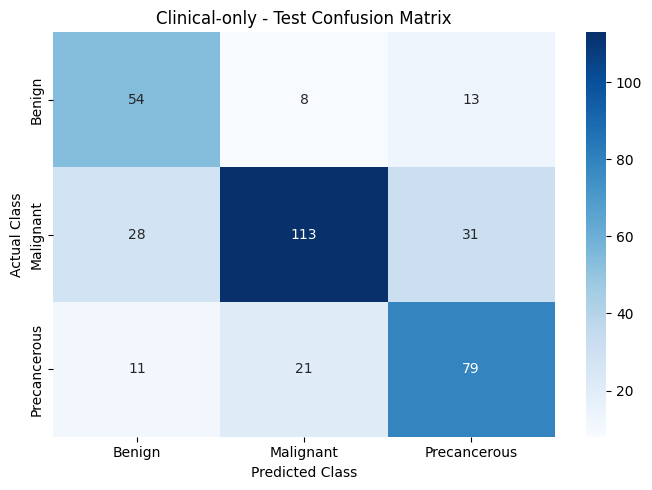

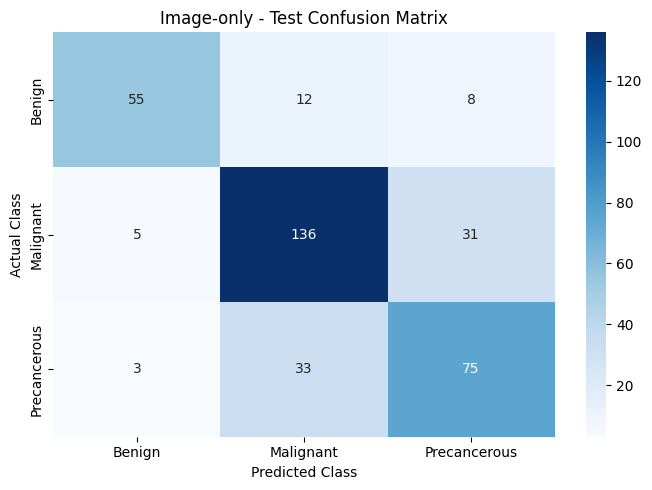

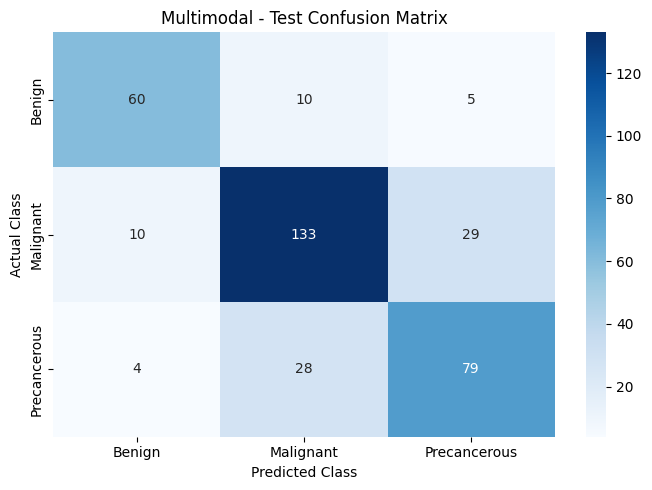

Three confusion matrix figures saved.


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from pathlib import Path

FIGURE_DIR = FINAL_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    )

    safe_name = model_name.lower().replace("-", "_")

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} - Test Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{safe_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("Three confusion matrix figures saved.")

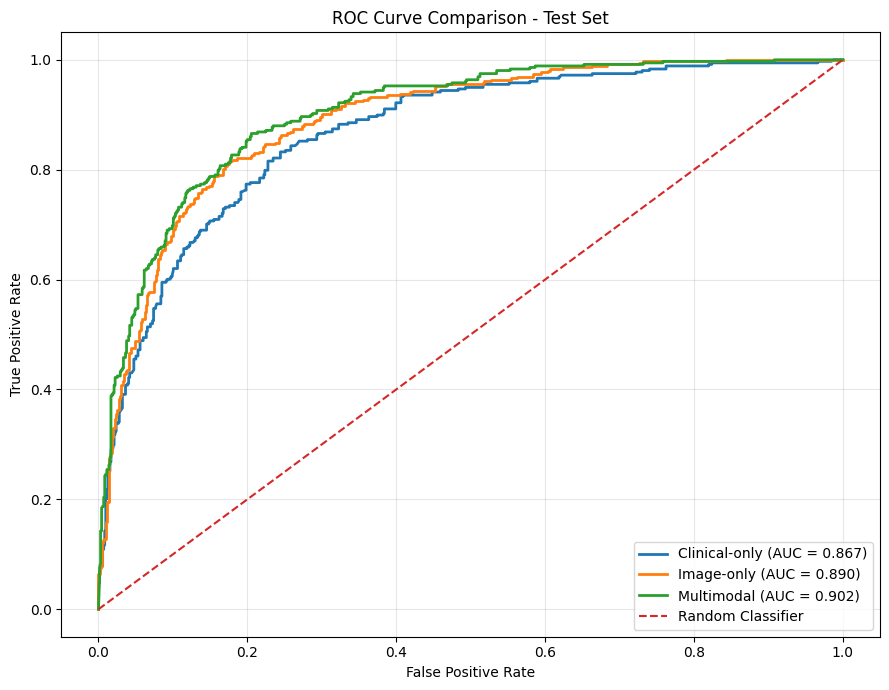

ROC curve saved successfully.


In [21]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true_binary = label_binarize(y_true, classes=[0, 1, 2])

plt.figure(figsize=(9, 7))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_true_binary.ravel(),
        probabilities.ravel()
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("ROC curve saved successfully.")


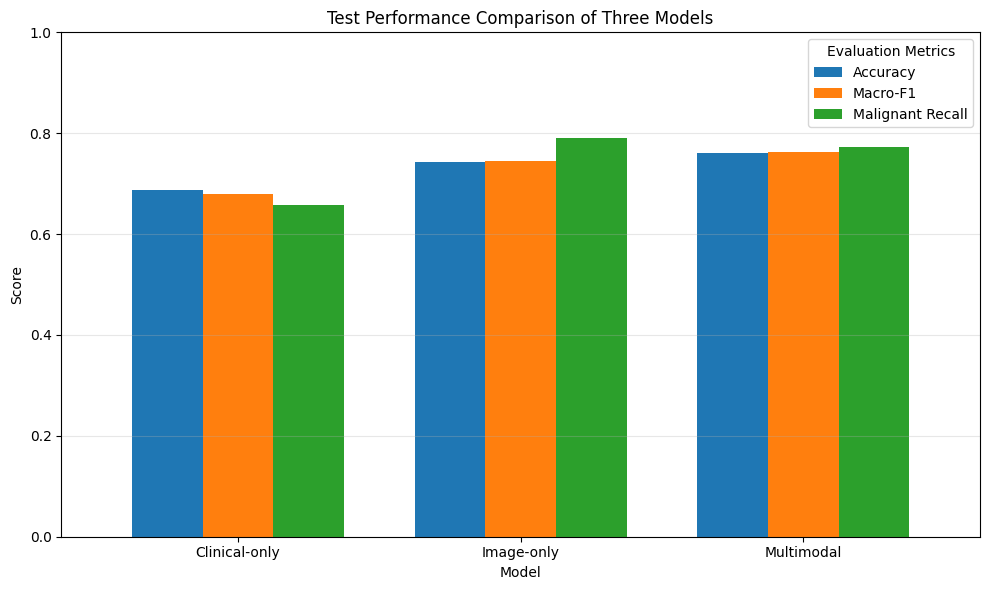

Model performance comparison saved.


In [22]:
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    "Accuracy",
    "Macro-F1",
    "Malignant Recall"
]

plot_data = final_results_df.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Test Performance Comparison of Three Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Model performance comparison saved.")

In [26]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

required_histories = [
    "finetuning_history.csv",
    "frozen_training_history.csv",
    "training_history.csv"
]

for filename in required_histories:
    matches = list(INPUT_DIR.rglob(filename))

    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND")


finetuning_history.csv:
FOUND: /kaggle/input/datasets/mannugaurav/pad-ufes-20-training-histories/finetuning_history.csv

frozen_training_history.csv:
FOUND: /kaggle/input/datasets/mannugaurav/pad-ufes-20-training-histories/frozen_training_history.csv

training_history.csv:
FOUND: /kaggle/input/datasets/mannugaurav/pad-ufes-20-training-histories/training_history.csv


In [27]:
HISTORY_DIR = Path(
    "/kaggle/input/datasets/mannugaurav/pad-ufes-20-training-histories"
)

image_history = pd.read_csv(
    HISTORY_DIR / "finetuning_history.csv"
)

frozen_history = pd.read_csv(
    HISTORY_DIR / "frozen_training_history.csv"
)

multimodal_history = pd.read_csv(
    HISTORY_DIR / "training_history.csv"
)

print("Image fine-tuning columns:")
print(image_history.columns.tolist())

print("\nFrozen training columns:")
print(frozen_history.columns.tolist())

print("\nMultimodal training columns:")
print(multimodal_history.columns.tolist())

print("\nImage fine-tuning sample:")
print(image_history.head())

print("\nMultimodal training sample:")
print(multimodal_history.head())

Image fine-tuning columns:
['epoch', 'train_loss', 'val_loss', 'val_accuracy', 'val_macro_f1']

Frozen training columns:
['epoch', 'train_loss', 'val_loss', 'val_accuracy', 'val_macro_f1']

Multimodal training columns:
['epoch', 'train_loss', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1']

Image fine-tuning sample:
   epoch  train_loss  val_loss  val_accuracy  val_macro_f1
0      1    0.573502  0.625116      0.760656      0.757897
1      2    0.433095  0.604511      0.737705      0.740057
2      3    0.353209  0.617098      0.770492      0.773636
3      4    0.275326  0.662401      0.734426      0.723027
4      5    0.206509  0.652359      0.754098      0.754028

Multimodal training sample:
   epoch  train_loss  train_macro_f1  val_loss  val_accuracy  val_macro_f1
0      1    0.218201        0.926747  0.818103      0.750820      0.752067
1      2    0.059913        0.975929  0.870571      0.763934      0.765310
2      3    0.058403        0.977521  0.879870      0.777049

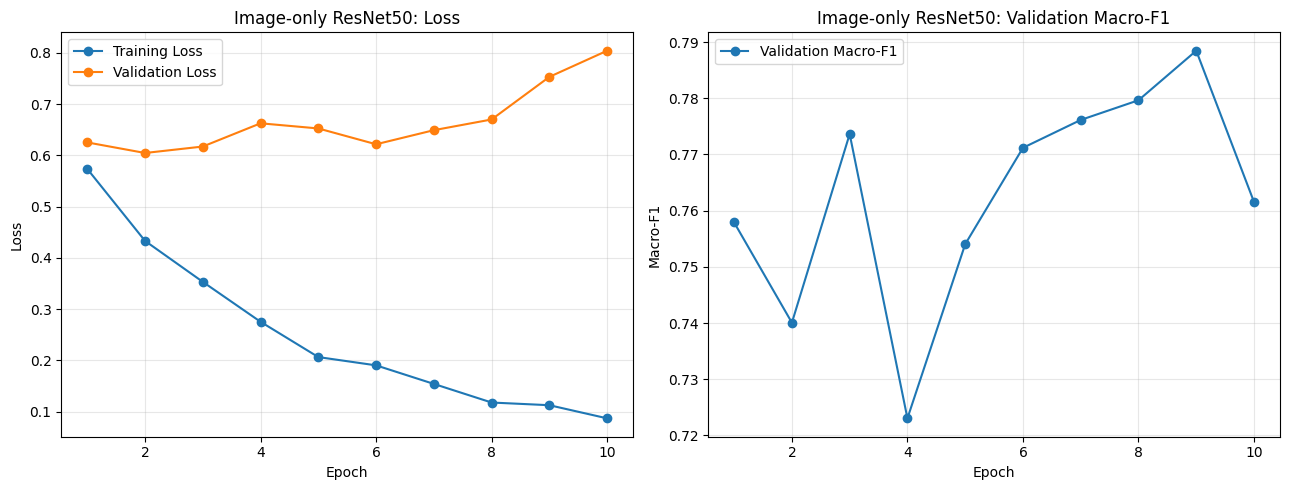

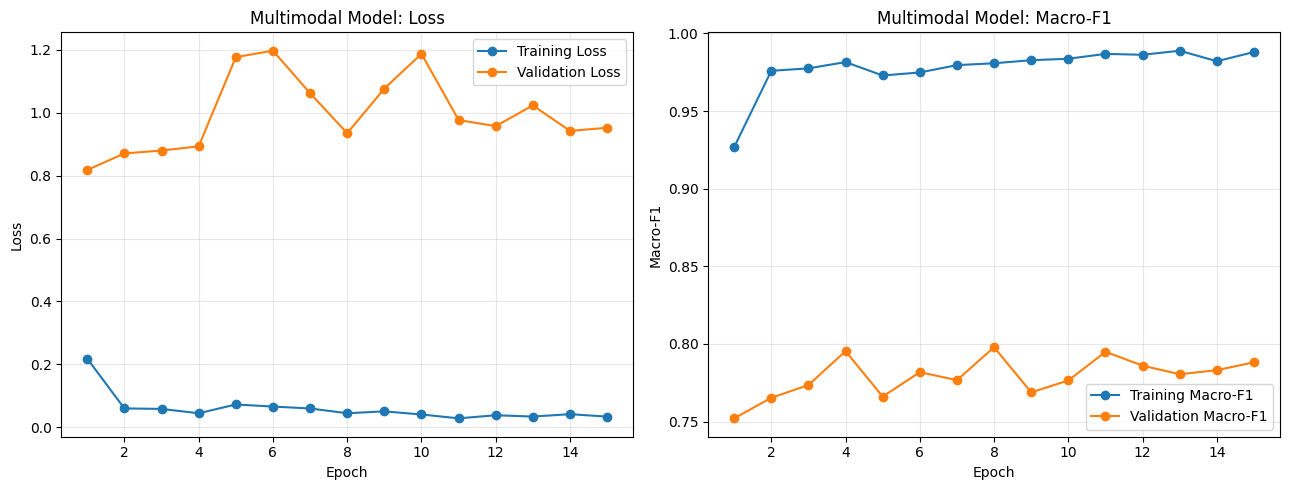

Both training curve figures saved successfully.


In [28]:
# Image-only training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    image_history["epoch"],
    image_history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    image_history["epoch"],
    image_history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Image-only ResNet50: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    image_history["epoch"],
    image_history["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)
axes[1].set_title("Image-only ResNet50: Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "image_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# Multimodal training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    multimodal_history["epoch"],
    multimodal_history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    multimodal_history["epoch"],
    multimodal_history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Multimodal Model: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    multimodal_history["epoch"],
    multimodal_history["train_macro_f1"],
    marker="o",
    label="Training Macro-F1"
)
axes[1].plot(
    multimodal_history["epoch"],
    multimodal_history["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)
axes[1].set_title("Multimodal Model: Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "multimodal_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Both training curve figures saved successfully.")

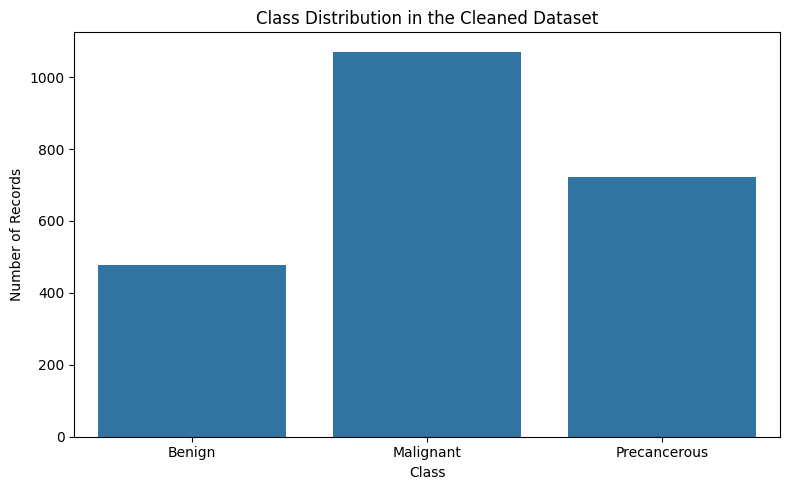

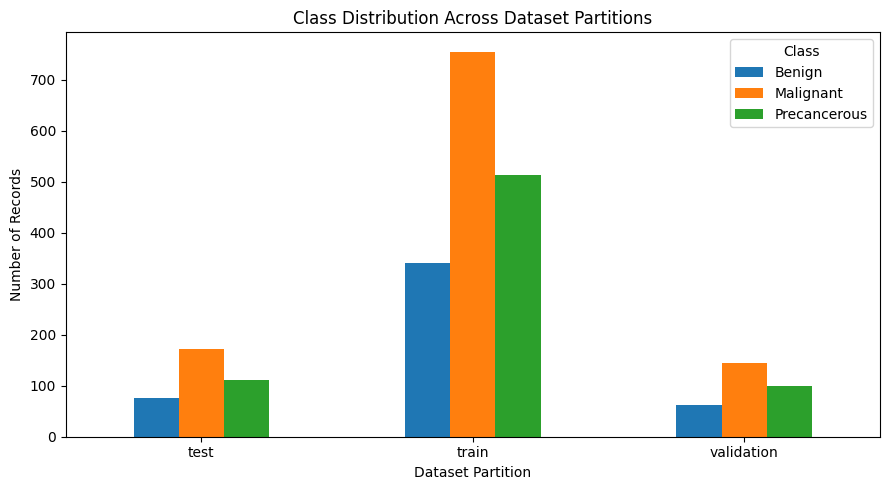

Dataset distribution figures saved.


In [29]:
# Overall class distribution
class_counts = df["target"].value_counts().reindex(class_names)

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Class Distribution in the Cleaned Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dataset_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Class distribution across partitions
split_counts = pd.crosstab(
    df["split"],
    df["target"]
).reindex(columns=class_names)

split_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Class Distribution Across Dataset Partitions")
plt.xlabel("Dataset Partition")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "split_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Dataset distribution figures saved.")

In [30]:
print("Saved figures:\n")

for file in sorted(FIGURE_DIR.glob("*.png")):
    print(f"{file.name} — {file.stat().st_size / 1024:.1f} KB")

print("\nTotal figures:", len(list(FIGURE_DIR.glob("*.png"))))

Saved figures:

clinical_only_confusion_matrix.png — 101.1 KB
dataset_class_distribution.png — 78.4 KB
image_only_confusion_matrix.png — 104.5 KB
image_training_curves.png — 240.6 KB
model_performance_comparison.png — 103.9 KB
multimodal_confusion_matrix.png — 104.7 KB
multimodal_training_curves.png — 217.7 KB
roc_curve_comparison.png — 210.8 KB
split_class_distribution.png — 104.3 KB

Total figures: 9


In [31]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/final_results",
    "zip",
    "/kaggle/working/final_results"
)

print("ZIP created:", zip_path)

ZIP created: /kaggle/working/final_results.zip
